In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Time calculation
import time

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# ANN classification model
from sklearn.neural_network import MLPClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
# Load the Dry Bean dataset
df = pd.read_excel("../data/Dry_Bean_Dataset.xlsx")

# Display the first five records
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
# Check the number of rows and columns
df.shape

(13611, 17)

In [4]:
# Check data types of all columns
df.dtypes

Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class                  str
dtype: object

In [5]:
# Check missing values in each column
df.isnull().sum()

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

In [6]:
# Count the number of samples in each class
df["Class"].value_counts()

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

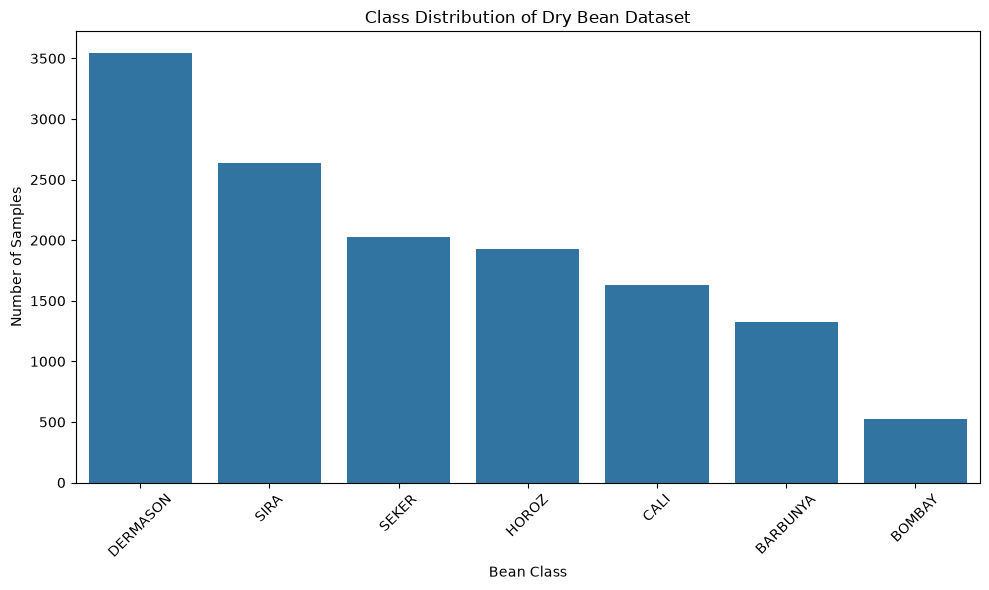

In [7]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Class",
    order=df["Class"].value_counts().index
)

plt.title("Class Distribution of Dry Bean Dataset")
plt.xlabel("Bean Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [8]:
# Generate descriptive statistics for numerical features
df.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [9]:
# Separate input features and target variable

X = df.drop("Class", axis=1)
y = df["Class"]

# Check their dimensions

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

Input features shape: (13611, 16)
Target variable shape: (13611,)


In [10]:
# Create a LabelEncoder object
label_encoder = LabelEncoder()

# Convert text class labels into numerical labels
y_encoded = label_encoder.fit_transform(y)

# Display the class mapping
print("Class Mapping:")

for class_name, encoded_value in zip(
    label_encoder.classes_,
    range(len(label_encoder.classes_))
):
    print(class_name, ":", encoded_value)

Class Mapping:
BARBUNYA : 0
BOMBAY : 1
CALI : 2
DERMASON : 3
HOROZ : 4
SEKER : 5
SIRA : 6


In [11]:
print("\nFirst 10 original labels:")
print(y.head(10).values)

print("\nFirst 10 encoded labels:")
print(y_encoded[:10])


First 10 original labels:
<ArrowStringArray>
['SEKER', 'SEKER', 'SEKER', 'SEKER', 'SEKER', 'SEKER', 'SEKER', 'SEKER',
 'SEKER', 'SEKER']
Length: 10, dtype: str

First 10 encoded labels:
[5 5 5 5 5 5 5 5 5 5]


In [12]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# Display the shapes

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (10888, 16)
Testing input shape: (2723, 16)
Training target shape: (10888,)
Testing target shape: (2723,)


In [13]:
# Create a StandardScaler object
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Check the shapes
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (10888, 16)
Scaled testing data shape: (2723, 16)


In [14]:
# Display the first five standardized training samples

print("First five standardized records:")
print(X_train_scaled[:5])

First five standardized records:
[[-0.3713618  -0.53113068 -0.69536968  0.08665715 -1.29379955 -1.51596432
  -0.38003852 -0.36109817  0.85742085  1.25610037  1.51686446  1.44683238
  -0.33981809  1.1180828   1.48524952  0.95141545]
 [ 0.02895235  0.49881788  0.78351767 -0.54035181  2.40181155  1.49345505
   0.03532258  0.15031994 -2.94171863 -0.84382916 -2.37816082 -1.99994765
   0.55140561 -1.32149685 -1.87953411  0.15816122]
 [ 0.72707783  0.79500482  0.82438155  0.92484936  0.07690248  0.33083582
   0.71712016  0.92324284  1.20311675  0.61879181  0.25449758 -0.20110382
  -1.16093136 -0.78767344 -0.2375073  -0.35302552]
 [ 0.73213127  0.8835923   1.02089657  0.72564285  0.61489533  0.72119375
   0.7353826   0.9284194   0.8704588  -0.47939515 -0.2539808  -0.71595896
  -0.96978627 -1.03243811 -0.7329069  -0.97350404]
 [-0.13350882 -0.25749702 -0.48124173  0.49413949 -1.38102267 -1.71349511
  -0.14403943 -0.04976599  0.71386324  1.24723519  1.53106032  1.56981612
  -0.78663151  0.919368

In [15]:
# Check the mean and standard deviation of scaled training features

print("Mean of scaled features:")
print(np.mean(X_train_scaled, axis=0))

print("\nStandard deviation of scaled features:")
print(np.std(X_train_scaled, axis=0))

Mean of scaled features:
[ 1.22034801e-16 -1.83378498e-16  2.12745162e-16 -2.77025525e-16
 -5.83417713e-16 -7.68101396e-16 -1.01151841e-16 -2.76699228e-16
 -4.50451987e-16  4.88791797e-15 -1.15769913e-15 -4.33974026e-16
  5.80807343e-16  2.85182931e-16  4.17659213e-17  3.23829460e-14]

Standard deviation of scaled features:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [16]:
ann_model = MLPClassifier(
    hidden_layer_sizes=(32, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=42
)

In [17]:
# Train the ANN model

start_time = time.time()

ann_model.fit(X_train_scaled, y_train)

end_time = time.time()

training_time = end_time - start_time

print("ANN Model Training Completed!")
print("Training Time:", round(training_time, 2), "seconds")
print("Number of Iterations:", ann_model.n_iter_)
print("Final Loss:", ann_model.loss_)

ANN Model Training Completed!
Training Time: 2.08 seconds
Number of Iterations: 55
Final Loss: 0.17569835923981839


In [18]:
# Predict bean classes using the trained ANN

y_pred = ann_model.predict(X_test_scaled)

print("First 10 Actual Classes:")
print(y_test[:10])

print("\nFirst 10 Predicted Classes:")
print(y_pred[:10])

First 10 Actual Classes:
[3 1 6 5 0 5 3 6 0 4]

First 10 Predicted Classes:
[3 1 6 5 0 5 3 6 2 4]


In [19]:
# Convert encoded values back to original bean names

actual_classes = label_encoder.inverse_transform(y_test)
predicted_classes = label_encoder.inverse_transform(y_pred)

print("First 10 Actual Bean Classes:")
print(actual_classes[:10])

print("\nFirst 10 Predicted Bean Classes:")
print(predicted_classes[:10])

First 10 Actual Bean Classes:
['DERMASON' 'BOMBAY' 'SIRA' 'SEKER' 'BARBUNYA' 'SEKER' 'DERMASON' 'SIRA'
 'BARBUNYA' 'HOROZ']

First 10 Predicted Bean Classes:
['DERMASON' 'BOMBAY' 'SIRA' 'SEKER' 'BARBUNYA' 'SEKER' 'DERMASON' 'SIRA'
 'CALI' 'HOROZ']


In [20]:
# Calculate ANN classification performance

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro"
)

recall = recall_score(
    y_test, y_pred, average="macro"
)

f1 = f1_score(
    y_test, y_pred, average="macro"
)

print("ANN Classification Performance")
print("--------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

ANN Classification Performance
--------------------------------
Accuracy : 0.9273
Precision: 0.9387
Recall   : 0.9366
F1-Score : 0.9376


In [21]:
# Generate detailed classification report

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.90      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.94      0.94      0.94       326
    DERMASON       0.92      0.92      0.92       709
       HOROZ       0.97      0.95      0.96       386
       SEKER       0.94      0.96      0.95       406
        SIRA       0.87      0.89      0.88       527

    accuracy                           0.93      2723
   macro avg       0.94      0.94      0.94      2723
weighted avg       0.93      0.93      0.93      2723



In [22]:
# Generate confusion matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[239   0  16   0   0   4   6]
 [  0 104   0   0   0   0   0]
 [ 11   0 305   0   6   2   2]
 [  0   0   0 653   0  10  46]
 [  2   0   4   6 368   0   6]
 [  2   0   0   5   0 389  10]
 [  3   0   0  42   7   8 467]]


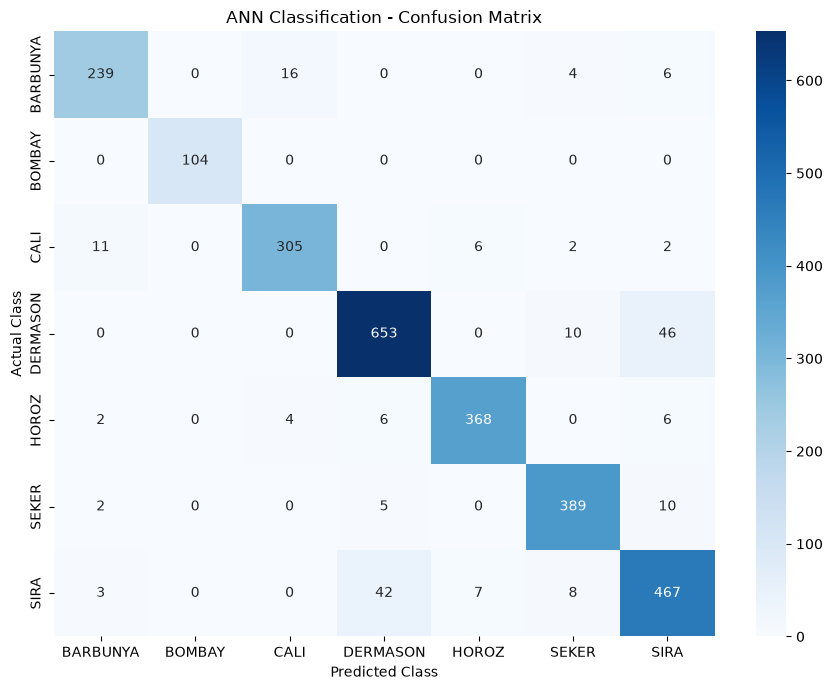

In [23]:
# Plot confusion matrix

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("ANN Classification - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

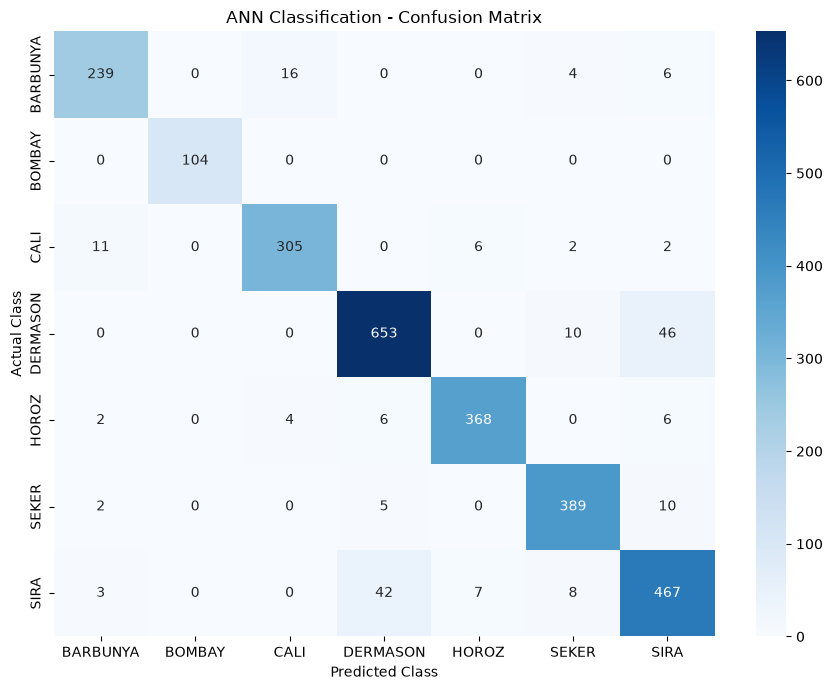

In [24]:
# Plot and save confusion matrix

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("ANN Classification - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

plt.savefig(
    "../figures/ANN_Confusion_Matrix_2HL_ReLU_LR001.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
# Create performance results DataFrame

ann_results = pd.DataFrame({
    "Hidden_Layers": [2],
    "Neurons_Per_Layer": [32],
    "Activation": ["relu"],
    "Learning_Rate": [0.001],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1_Score": [f1],
    "Training_Time": [training_time],
    "Iterations": [ann_model.n_iter_],
    "Final_Loss": [ann_model.loss_]
})

# Save results as CSV

ann_results.to_csv(
    "../results/ANN_First_Model_Performance.csv",
    index=False
)

ann_results

,Hidden_Layers,Neurons_Per_Layer,Activation,Learning_Rate,Accuracy,Precision,Recall,F1_Score,Training_Time,Iterations,Final_Loss
0,2,32,relu,0.001,0.927286,0.938681,0.93659,0.937577,2.084562,55,0.175698


In [26]:
# Define ANN experimental parameters

hidden_layer_counts = range(2, 11)

activation_functions = [
    "relu",
    "logistic",
    "tanh"
]

learning_rates = [
    0.0001,
    0.001,
    0.01
]

# Calculate total number of experiments

total_experiments = (
    len(hidden_layer_counts)
    * len(activation_functions)
    * len(learning_rates)
)

print("ANN Experimental Parameters")
print("----------------------------")
print("Hidden layer counts:", list(hidden_layer_counts))
print("Activation functions:", activation_functions)
print("Learning rates:", learning_rates)
print("Total experiments:", total_experiments)

ANN Experimental Parameters
----------------------------
Hidden layer counts: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Activation functions: ['relu', 'logistic', 'tanh']
Learning rates: [0.0001, 0.001, 0.01]
Total experiments: 81


In [27]:
# Generate hidden-layer architectures

architectures = []

for n_layers in hidden_layer_counts:

    architecture = (32,) * n_layers

    architectures.append(architecture)

# Display architectures

for architecture in architectures:
    print(architecture)

(32, 32)
(32, 32, 32)
(32, 32, 32, 32)
(32, 32, 32, 32, 32)
(32, 32, 32, 32, 32, 32)
(32, 32, 32, 32, 32, 32, 32)
(32, 32, 32, 32, 32, 32, 32, 32)
(32, 32, 32, 32, 32, 32, 32, 32, 32)
(32, 32, 32, 32, 32, 32, 32, 32, 32, 32)


In [28]:
# Create an empty list to store ANN experiment results

experiment_results = []

print("Experiment results list created successfully.")

print("Initial number of records:", len(experiment_results))

Experiment results list created successfully.
Initial number of records: 0


In [29]:
# Test the nested loops

combination_count = 0

for n_layers in hidden_layer_counts:

    for activation in activation_functions:

        for lr in learning_rates:

            combination_count += 1

print("Total combinations generated:", combination_count)

Total combinations generated: 81


In [30]:
# Generate ANN model configurations

for n_layers in hidden_layer_counts:

    for activation in activation_functions:

        for lr in learning_rates:

            hidden_sizes = (32,) * n_layers

            ann_model = MLPClassifier(
                hidden_layer_sizes=hidden_sizes,
                activation=activation,
                solver="adam",
                learning_rate_init=lr,
                max_iter=200,
                early_stopping=True,
                validation_fraction=0.1,
                n_iter_no_change=15,
                random_state=42
            )

print("All 81 ANN model configurations prepared.")

All 81 ANN model configurations prepared.


In [31]:
# Train and evaluate all 81 ANN models

experiment_results = []

experiment_number = 0

for n_layers in hidden_layer_counts:

    for activation in activation_functions:

        for lr in learning_rates:

            experiment_number += 1

            # Generate hidden layer architecture
            hidden_sizes = (32,) * n_layers

            # Create ANN model
            ann_model = MLPClassifier(
                hidden_layer_sizes=hidden_sizes,
                activation=activation,
                solver="adam",
                learning_rate_init=lr,
                max_iter=200,
                early_stopping=True,
                validation_fraction=0.1,
                n_iter_no_change=15,
                random_state=42
            )

            # Start training time
            start_time = time.time()

            # Train ANN
            ann_model.fit(X_train_scaled, y_train)

            # End training time
            end_time = time.time()

            training_time = end_time - start_time

            # Generate predictions
            y_pred = ann_model.predict(X_test_scaled)

            # Calculate performance metrics
            accuracy = accuracy_score(y_test, y_pred)

            precision = precision_score(
                y_test, y_pred, average="macro", zero_division=0
            )

            recall = recall_score(
                y_test, y_pred, average="macro", zero_division=0
            )

            f1 = f1_score(
                y_test, y_pred, average="macro", zero_division=0
            )

            # Store experiment results
            experiment_results.append({
                "Hidden_Layers": n_layers,
                "Neurons_Per_Layer": 32,
                "Activation": activation,
                "Learning_Rate": lr,
                "Accuracy": accuracy,
                "Precision": precision,
                "Recall": recall,
                "F1_Score": f1,
                "Training_Time": training_time,
                "Iterations": ann_model.n_iter_,
                "Final_Loss": ann_model.loss_
            })

            print(
                f"Experiment {experiment_number}/81 completed | "
                f"Layers: {n_layers} | "
                f"Activation: {activation} | "
                f"LR: {lr}"
            )

print("\nAll ANN experiments completed!")

Experiment 1/81 completed | Layers: 2 | Activation: relu | LR: 0.0001
Experiment 2/81 completed | Layers: 2 | Activation: relu | LR: 0.001
Experiment 3/81 completed | Layers: 2 | Activation: relu | LR: 0.01


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Experiment 4/81 completed | Layers: 2 | Activation: logistic | LR: 0.0001
Experiment 5/81 completed | Layers: 2 | Activation: logistic | LR: 0.001
Experiment 6/81 completed | Layers: 2 | Activation: logistic | LR: 0.01
Experiment 7/81 completed | Layers: 2 | Activation: tanh | LR: 0.0001
Experiment 8/81 completed | Layers: 2 | Activation: tanh | LR: 0.001
Experiment 9/81 completed | Layers: 2 | Activation: tanh | LR: 0.01
Experiment 10/81 completed | Layers: 3 | Activation: relu | LR: 0.0001
Experiment 11/81 completed | Layers: 3 | Activation: relu | LR: 0.001
Experiment 12/81 completed | Layers: 3 | Activation: relu | LR: 0.01
Experiment 13/81 completed | Layers: 3 | Activation: logistic | LR: 0.0001
Experiment 14/81 completed | Layers: 3 | Activation: logistic | LR: 0.001
Experiment 15/81 completed | Layers: 3 | Activation: logistic | LR: 0.01
Experiment 16/81 completed | Layers: 3 | Activation: tanh | LR: 0.0001
Experiment 17/81 completed | Layers: 3 | Activation: tanh | LR: 0.001
E

In [2]:
import pandas as pd

In [4]:
print("Checking experiment results...")

try:
    print("Number of experiments:", len(experiment_results))
except NameError:
    print("Experiment results are not available in memory.")

Checking experiment results...
Experiment results are not available in memory.


In [5]:
experiment_results = []

print("Experiment results list created successfully.")

Experiment results list created successfully.


In [6]:
# Number of hidden layers to test
hidden_layer_counts = range(2, 11)

# Activation functions
activation_functions = ["relu", "logistic", "tanh"]

# Learning rates
learning_rates = [0.0001, 0.001, 0.01]

# Total number of experiments
total_experiments = (
    len(hidden_layer_counts)
    * len(activation_functions)
    * len(learning_rates)
)

print("Hidden layer counts:", list(hidden_layer_counts))
print("Activation functions:", activation_functions)
print("Learning rates:", learning_rates)
print("Total experiments:", total_experiments)

Hidden layer counts: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Activation functions: ['relu', 'logistic', 'tanh']
Learning rates: [0.0001, 0.001, 0.01]
Total experiments: 81


In [7]:
print("Checking required variables...")

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("MLPClassifier:", MLPClassifier)
print("Pandas:", pd.__version__)

Checking required variables...


NameError: name 'X_train_scaled' is not defined

In [8]:
print(df.shape)
print(df.head())

NameError: name 'df' is not defined

In [9]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [10]:
# Load the Dry Bean dataset
df = pd.read_excel("../data/Dry_Bean_Dataset.xlsx")

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [11]:
# Separate input features
X = df.drop("Class", axis=1)

# Separate target variable
y = df["Class"]

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nTarget classes:")
print(y.unique())

Input features shape: (13611, 16)
Target variable shape: (13611,)

Target classes:
<ArrowStringArray>
['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON']
Length: 7, dtype: str


In [12]:
# Create LabelEncoder
label_encoder = LabelEncoder()

# Convert text classes into numerical labels
y_encoded = label_encoder.fit_transform(y)

print("Class encoding:")

for class_name, encoded_value in zip(
    label_encoder.classes_,
    range(len(label_encoder.classes_))
):
    print(class_name, ":", encoded_value)

print("\nFirst 10 encoded values:")
print(y_encoded[:10])

Class encoding:
BARBUNYA : 0
BOMBAY : 1
CALI : 2
DERMASON : 3
HOROZ : 4
SEKER : 5
SIRA : 6

First 10 encoded values:
[5 5 5 5 5 5 5 5 5 5]


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (10888, 16)
Testing features: (2723, 16)
Training labels: (10888,)
Testing labels: (2723,)


In [14]:
# Create StandardScaler
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

print("\nMean of scaled training features:")
print(np.mean(X_train_scaled, axis=0))

print("\nStandard deviation of scaled training features:")
print(np.std(X_train_scaled, axis=0))

Scaled training data: (10888, 16)
Scaled testing data: (2723, 16)

Mean of scaled training features:
[ 1.22034801e-16 -1.83378498e-16  2.12745162e-16 -2.77025525e-16
 -5.83417713e-16 -7.68101396e-16 -1.01151841e-16 -2.76699228e-16
 -4.50451987e-16  4.88791797e-15 -1.15769913e-15 -4.33974026e-16
  5.80807343e-16  2.85182931e-16  4.17659213e-17  3.23829460e-14]

Standard deviation of scaled training features:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [15]:
print("Training features:", X_train_scaled.shape)
print("Testing features:", X_test_scaled.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nNumber of classes:", len(label_encoder.classes_))
print("Classes:", label_encoder.classes_)

print("\nAll required variables are ready!")

Training features: (10888, 16)
Testing features: (2723, 16)
Training labels: (10888,)
Testing labels: (2723,)

Number of classes: 7
Classes: ['BARBUNYA' 'BOMBAY' 'CALI' 'DERMASON' 'HOROZ' 'SEKER' 'SIRA']

All required variables are ready!


In [16]:
# Initialize results storage
experiment_results = []

# Hidden layer configurations
hidden_layer_counts = range(2, 11)

# Activation functions
activation_functions = ["relu", "logistic", "tanh"]

# Learning rates
learning_rates = [0.0001, 0.001, 0.01]

print("Experiment settings restored!")
print("Total experiments:",
      len(hidden_layer_counts)
      * len(activation_functions)
      * len(learning_rates))

Experiment settings restored!
Total experiments: 81


In [17]:
experiment_number = 0

for n_layers in hidden_layer_counts:

    for activation in activation_functions:

        for lr in learning_rates:

            experiment_number += 1

            # Define ANN architecture
            hidden_sizes = (32,) * n_layers

            # Create ANN model
            ann_model = MLPClassifier(
                hidden_layer_sizes=hidden_sizes,
                activation=activation,
                solver="adam",
                learning_rate_init=lr,
                max_iter=200,
                early_stopping=True,
                validation_fraction=0.1,
                n_iter_no_change=15,
                random_state=42
            )

            # Train the model
            start_time = time.time()

            ann_model.fit(X_train_scaled, y_train)

            end_time = time.time()
            training_time = end_time - start_time

            # Predict test data
            y_pred = ann_model.predict(X_test_scaled)

            # Calculate performance metrics
            accuracy = accuracy_score(y_test, y_pred)

            precision = precision_score(
                y_test, y_pred,
                average="macro",
                zero_division=0
            )

            recall = recall_score(
                y_test, y_pred,
                average="macro",
                zero_division=0
            )

            f1 = f1_score(
                y_test, y_pred,
                average="macro",
                zero_division=0
            )

            # Store experiment results
            experiment_results.append({
                "Hidden_Layers": n_layers,
                "Neurons_Per_Layer": 32,
                "Activation": activation,
                "Learning_Rate": lr,
                "Accuracy": accuracy,
                "Precision": precision,
                "Recall": recall,
                "F1_Score": f1,
                "Training_Time": training_time,
                "Iterations": ann_model.n_iter_,
                "Final_Loss": ann_model.loss_
            })

            print(
                f"Experiment {experiment_number}/81 completed | "
                f"Layers: {n_layers} | "
                f"Activation: {activation} | "
                f"LR: {lr}"
            )

print("\nAll ANN experiments completed!")

Experiment 1/81 completed | Layers: 2 | Activation: relu | LR: 0.0001
Experiment 2/81 completed | Layers: 2 | Activation: relu | LR: 0.001
Experiment 3/81 completed | Layers: 2 | Activation: relu | LR: 0.01


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Experiment 4/81 completed | Layers: 2 | Activation: logistic | LR: 0.0001
Experiment 5/81 completed | Layers: 2 | Activation: logistic | LR: 0.001
Experiment 6/81 completed | Layers: 2 | Activation: logistic | LR: 0.01
Experiment 7/81 completed | Layers: 2 | Activation: tanh | LR: 0.0001
Experiment 8/81 completed | Layers: 2 | Activation: tanh | LR: 0.001
Experiment 9/81 completed | Layers: 2 | Activation: tanh | LR: 0.01
Experiment 10/81 completed | Layers: 3 | Activation: relu | LR: 0.0001
Experiment 11/81 completed | Layers: 3 | Activation: relu | LR: 0.001
Experiment 12/81 completed | Layers: 3 | Activation: relu | LR: 0.01
Experiment 13/81 completed | Layers: 3 | Activation: logistic | LR: 0.0001
Experiment 14/81 completed | Layers: 3 | Activation: logistic | LR: 0.001
Experiment 15/81 completed | Layers: 3 | Activation: logistic | LR: 0.01
Experiment 16/81 completed | Layers: 3 | Activation: tanh | LR: 0.0001
Experiment 17/81 completed | Layers: 3 | Activation: tanh | LR: 0.001
E

In [18]:
results_df = pd.DataFrame(experiment_results)

print("Total ANN experiments:", len(results_df))

print("\nResults DataFrame Shape:")
print(results_df.shape)

print("\nFirst 10 Experiment Results:")
display(results_df.head(10))

Total ANN experiments: 81

Results DataFrame Shape:
(81, 11)

First 10 Experiment Results:


,Hidden_Layers,Neurons_Per_Layer,Activation,Learning_Rate,Accuracy,Precision,Recall,F1_Score,Training_Time,Iterations,Final_Loss
0,2,32,relu,0.0001,0.923614,0.938149,0.933071,0.935354,4.921696,118,0.197078
1,2,32,relu,0.0010,0.927286,0.938681,0.936590,0.937577,2.426530,55,0.175698
2,2,32,relu,0.0100,0.916269,0.932233,0.925800,0.928801,1.344715,24,0.175397
3,2,32,logistic,0.0001,0.914433,0.929657,0.922996,0.926095,9.376749,200,0.295784
4,2,32,logistic,0.0010,0.920676,0.933092,0.930840,0.931920,4.539868,93,0.194873
5,2,32,logistic,0.0100,0.928388,0.939996,0.938129,0.938976,3.070940,58,0.169734
6,2,32,tanh,0.0001,0.917738,0.932059,0.928613,0.930181,3.609946,79,0.225104
7,2,32,tanh,0.0010,0.923981,0.937409,0.933740,0.935448,3.368872,68,0.174159
8,2,32,tanh,0.0100,0.922145,0.938384,0.930062,0.933983,1.312202,24,0.175363
9,3,32,relu,0.0001,0.920308,0.934572,0.930949,0.932681,5.583664,90,0.200761


In [19]:
print("Total experiments:", len(results_df))

print("\nMissing values in each column:")
print(results_df.isnull().sum())

print("\nExperiments grouped by hidden layers:")
print(results_df.groupby("Hidden_Layers").size())

Total experiments: 81

Missing values in each column:
Hidden_Layers        0
Neurons_Per_Layer    0
Activation           0
Learning_Rate        0
Accuracy             0
Precision            0
Recall               0
F1_Score             0
Training_Time        0
Iterations           0
Final_Loss           0
dtype: int64

Experiments grouped by hidden layers:
Hidden_Layers
2     9
3     9
4     9
5     9
6     9
7     9
8     9
9     9
10    9
dtype: int64


In [20]:
results_df.to_csv(
    "../results/ANN_Classification_Experiment_Results.csv",
    index=False
)

print("ANN experiment results saved successfully!")

ANN experiment results saved successfully!


In [21]:
# Sort experiments by F1-score in descending order
results_sorted = results_df.sort_values(
    by="F1_Score",
    ascending=False
)

# Display the top 10 models
print("Top 10 ANN Models Based on Macro F1-Score:")

display(
    results_sorted[
        [
            "Hidden_Layers",
            "Neurons_Per_Layer",
            "Activation",
            "Learning_Rate",
            "Accuracy",
            "Precision",
            "Recall",
            "F1_Score",
            "Training_Time",
            "Iterations"
        ]
    ].head(10)
)

Top 10 ANN Models Based on Macro F1-Score:


,Hidden_Layers,Neurons_Per_Layer,Activation,Learning_Rate,Accuracy,Precision,Recall,F1_Score,Training_Time,Iterations
20,4,32,relu,0.0100,0.928021,0.940478,0.939432,0.939791,3.115910,39
5,2,32,logistic,0.0100,0.928388,0.939996,0.938129,0.938976,3.070940,58
28,5,32,relu,0.0010,0.927653,0.940702,0.937366,0.938928,5.105798,69
27,5,32,relu,0.0001,0.926552,0.940351,0.936854,0.938490,7.275442,89
1,2,32,relu,0.0010,0.927286,0.938681,0.936590,0.937577,2.426530,55
54,8,32,relu,0.0001,0.925083,0.939693,0.933858,0.936545,6.432352,57
11,3,32,relu,0.0100,0.925450,0.938122,0.935305,0.936544,1.239408,26
18,4,32,relu,0.0001,0.924715,0.938045,0.934933,0.936378,5.481427,85
46,7,32,relu,0.0010,0.924348,0.937496,0.935148,0.936264,3.451450,33
61,8,32,tanh,0.0010,0.925817,0.937429,0.933933,0.935629,5.699634,42


In [22]:
activation_comparison = results_df.groupby(
    "Activation"
)[
    ["Accuracy", "Precision", "Recall", "F1_Score", "Training_Time"]
].mean().reset_index()

print("Average Performance by Activation Function:")

display(activation_comparison)

Average Performance by Activation Function:


,Activation,Accuracy,Precision,Recall,F1_Score,Training_Time
0,logistic,0.577277,0.464303,0.515522,0.469572,4.489212
1,relu,0.922145,0.935732,0.932484,0.933867,4.631920
2,tanh,0.920349,0.933070,0.930202,0.931400,5.043398


In [23]:
learning_rate_comparison = results_df.groupby(
    "Learning_Rate"
)[
    ["Accuracy", "Precision", "Recall", "F1_Score", "Training_Time"]
].mean().reset_index()

print("Average Performance by Learning Rate:")

display(learning_rate_comparison)

Average Performance by Learning Rate:


,Learning_Rate,Accuracy,Precision,Recall,F1_Score,Training_Time
0,0.0001,0.725072,0.670523,0.697394,0.673801,5.587116
1,0.0010,0.847581,0.828994,0.837597,0.826357,4.939890
2,0.0100,0.847119,0.833588,0.843218,0.834681,3.637525


In [24]:
hidden_layer_comparison = results_df.groupby(
    "Hidden_Layers"
)[
    ["Accuracy", "Precision", "Recall", "F1_Score", "Training_Time"]
].mean().reset_index()

print("Average Performance by Number of Hidden Layers:")

display(hidden_layer_comparison)

Average Performance by Number of Hidden Layers:


,Hidden_Layers,Accuracy,Precision,Recall,F1_Score,Training_Time
0,2,0.921614,0.935518,0.931093,0.933148,3.774613
1,3,0.847187,0.834289,0.842768,0.834928,2.889004
2,4,0.849268,0.841761,0.845290,0.837330,4.064796
3,5,0.848533,0.836140,0.844166,0.836439,5.577691
4,6,0.846248,0.831952,0.841153,0.832790,6.095648
5,7,0.831109,0.792812,0.811404,0.797223,5.385620
6,8,0.716367,0.659675,0.683817,0.652667,5.077238
7,9,0.699596,0.633967,0.667173,0.640100,4.705656
8,10,0.699392,0.633201,0.667762,0.639892,4.923328


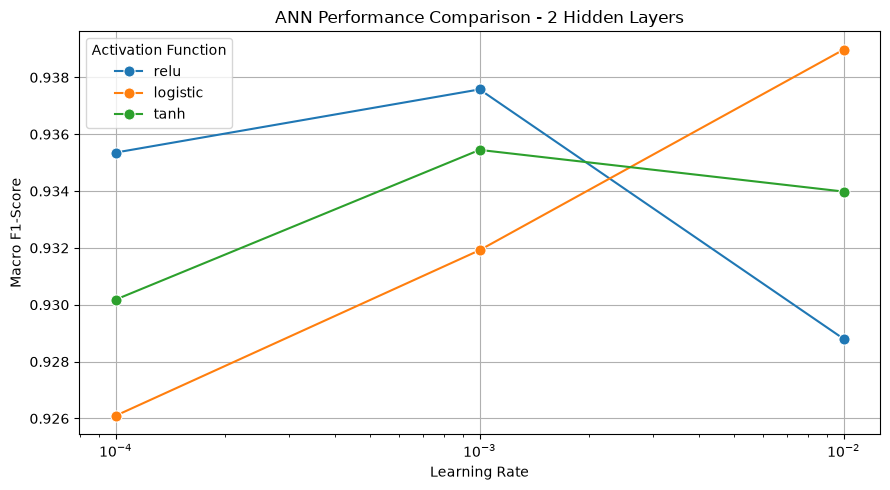

In [25]:
# Filter results for 2 hidden layers
data_2_layers = results_df[
    results_df["Hidden_Layers"] == 2
]

# Create comparison graph
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=data_2_layers,
    x="Learning_Rate",
    y="F1_Score",
    hue="Activation",
    marker="o",
    markersize=8
)

plt.title("ANN Performance Comparison - 2 Hidden Layers")
plt.xlabel("Learning Rate")
plt.ylabel("Macro F1-Score")

plt.xscale("log")
plt.grid(True)

plt.legend(title="Activation Function")
plt.tight_layout()

plt.show()

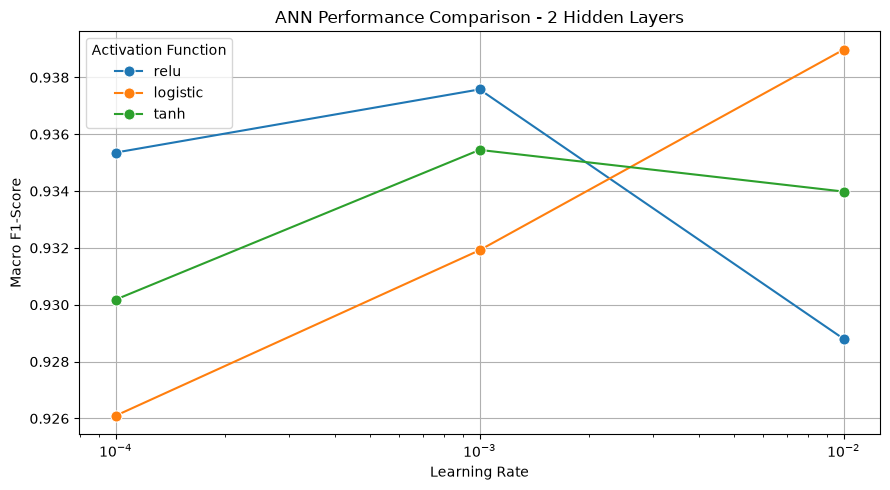

In [26]:
# Filter results for 2 hidden layers
data_2_layers = results_df[
    results_df["Hidden_Layers"] == 2
]

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=data_2_layers,
    x="Learning_Rate",
    y="F1_Score",
    hue="Activation",
    marker="o",
    markersize=8
)

plt.title("ANN Performance Comparison - 2 Hidden Layers")
plt.xlabel("Learning Rate")
plt.ylabel("Macro F1-Score")

plt.xscale("log")
plt.grid(True)

plt.legend(title="Activation Function")
plt.tight_layout()

# Save graph
plt.savefig(
    "../figures/ANN_F1_Comparison_2_Hidden_Layers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

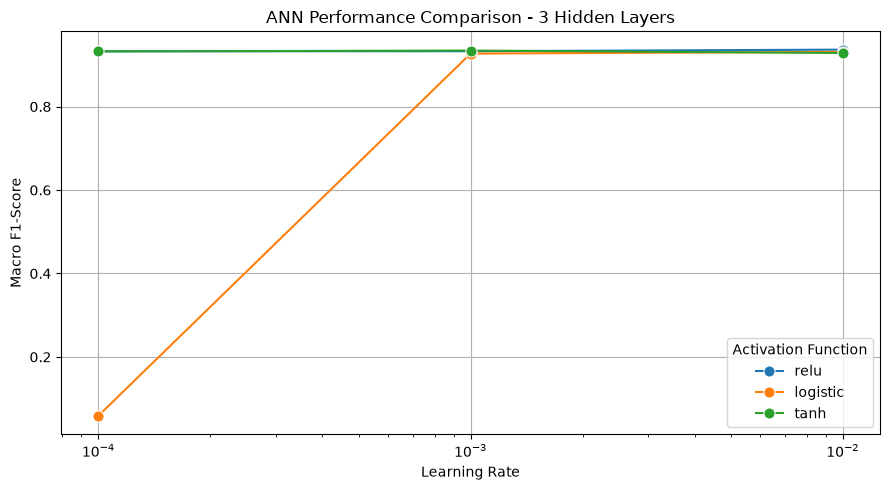

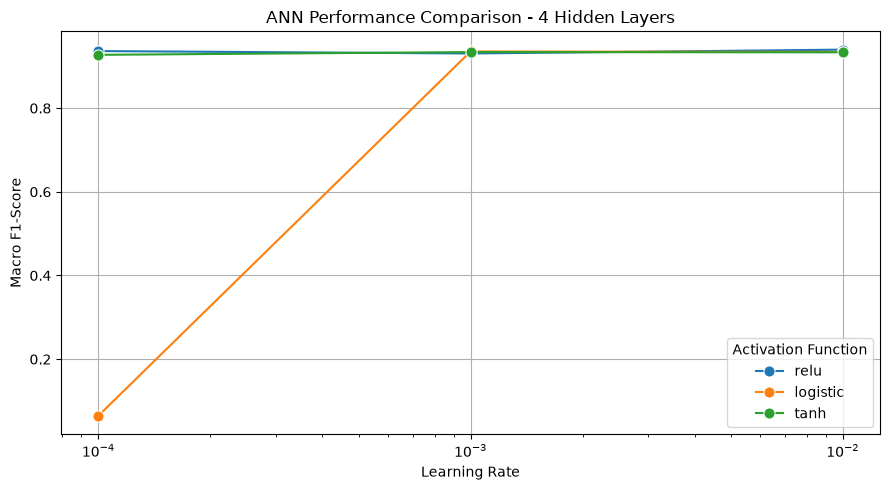

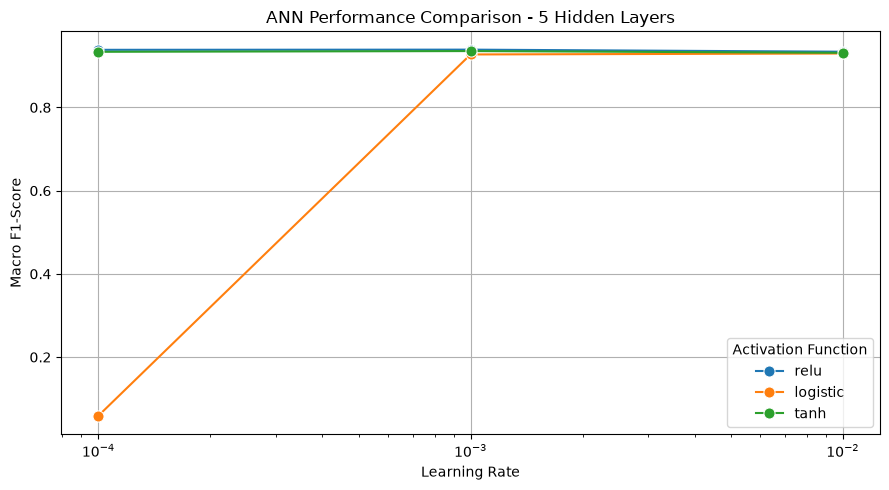

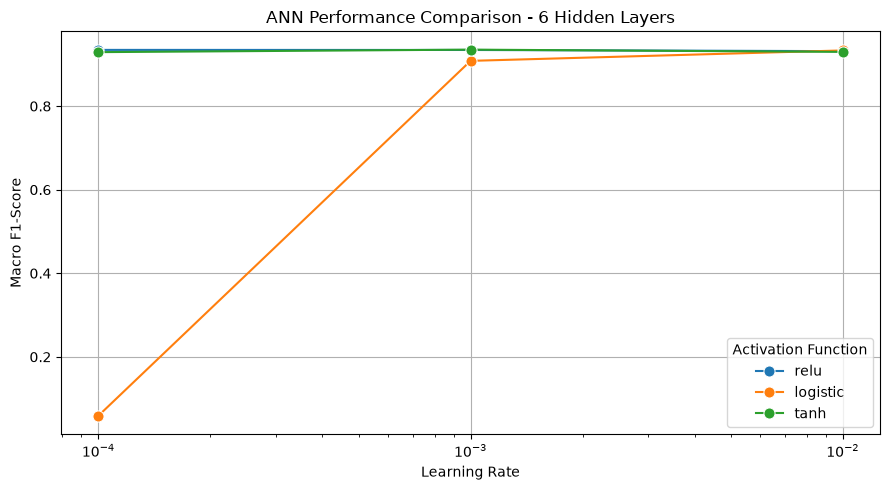

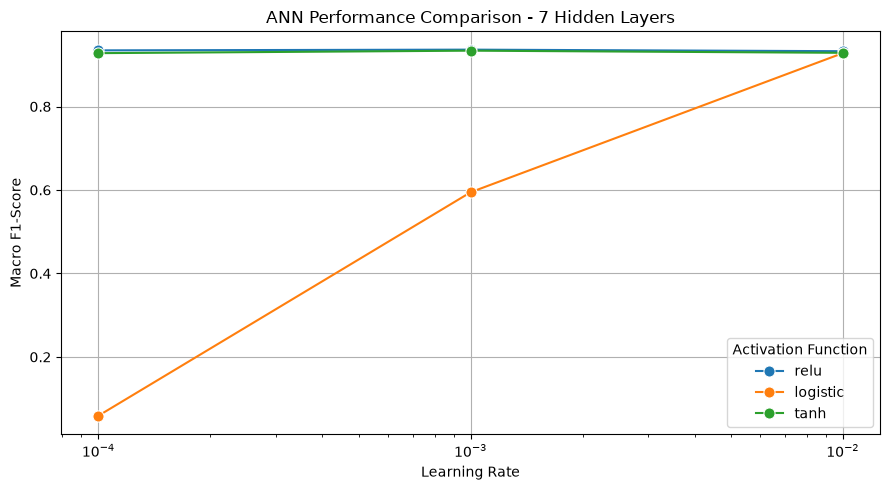

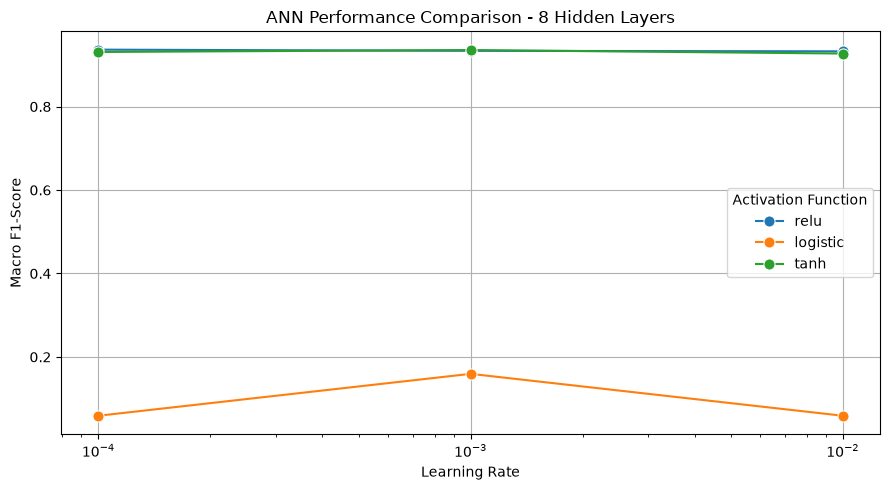

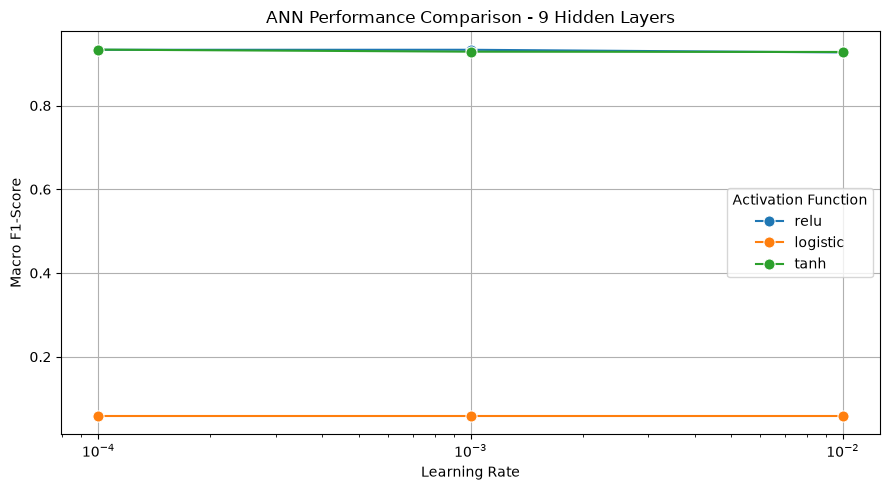

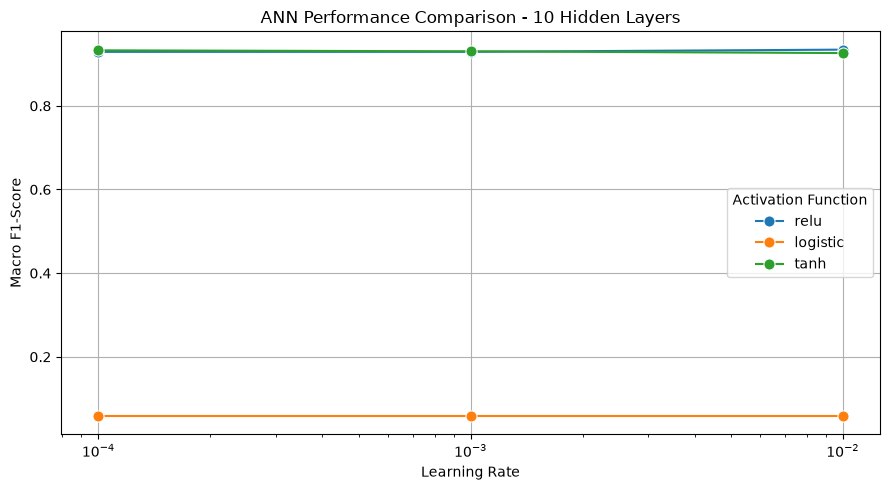

All 8 remaining graphs generated and saved successfully!


In [27]:
# Generate graphs for 3 to 10 hidden layers

for layers in range(3, 11):

    # Filter results for the current hidden-layer count
    layer_data = results_df[
        results_df["Hidden_Layers"] == layers
    ]

    # Create graph
    plt.figure(figsize=(9, 5))

    sns.lineplot(
        data=layer_data,
        x="Learning_Rate",
        y="F1_Score",
        hue="Activation",
        marker="o",
        markersize=8
    )

    plt.title(
        f"ANN Performance Comparison - {layers} Hidden Layers"
    )

    plt.xlabel("Learning Rate")
    plt.ylabel("Macro F1-Score")

    plt.xscale("log")
    plt.grid(True)

    plt.legend(title="Activation Function")
    plt.tight_layout()

    # Save each graph separately
    plt.savefig(
        f"../figures/ANN_F1_Comparison_{layers}_Hidden_Layers.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

print("All 8 remaining graphs generated and saved successfully!")

In [28]:
import os

figure_files = os.listdir("../figures")

ann_graphs = [
    file for file in figure_files
    if file.startswith("ANN_F1_Comparison_")
]

print("Total ANN comparison graphs:", len(ann_graphs))

for file in sorted(ann_graphs):
    print(file)

Total ANN comparison graphs: 9
ANN_F1_Comparison_10_Hidden_Layers.png
ANN_F1_Comparison_2_Hidden_Layers.png
ANN_F1_Comparison_3_Hidden_Layers.png
ANN_F1_Comparison_4_Hidden_Layers.png
ANN_F1_Comparison_5_Hidden_Layers.png
ANN_F1_Comparison_6_Hidden_Layers.png
ANN_F1_Comparison_7_Hidden_Layers.png
ANN_F1_Comparison_8_Hidden_Layers.png
ANN_F1_Comparison_9_Hidden_Layers.png


In [29]:
# Calculate average performance by activation function

activation_comparison = results_df.groupby(
    "Activation"
)[
    ["Accuracy", "Precision", "Recall", "F1_Score", "Training_Time"]
].mean().reset_index()

print("Average Performance by Activation Function:")
display(activation_comparison.round(4))

Average Performance by Activation Function:


,Activation,Accuracy,Precision,Recall,F1_Score,Training_Time
0,logistic,0.5773,0.4643,0.5155,0.4696,4.4892
1,relu,0.9221,0.9357,0.9325,0.9339,4.6319
2,tanh,0.9203,0.9331,0.9302,0.9314,5.0434


In [30]:
# Calculate average performance by learning rate

lr_comparison = results_df.groupby(
    "Learning_Rate"
)[
    ["Accuracy", "Precision", "Recall", "F1_Score", "Training_Time"]
].mean().reset_index()

print("Average Performance by Learning Rate:")
display(lr_comparison.round(4))

Average Performance by Learning Rate:


,Learning_Rate,Accuracy,Precision,Recall,F1_Score,Training_Time
0,0.0001,0.7251,0.6705,0.6974,0.6738,5.5871
1,0.0010,0.8476,0.8290,0.8376,0.8264,4.9399
2,0.0100,0.8471,0.8336,0.8432,0.8347,3.6375


In [31]:
# Calculate average performance by hidden-layer count

layer_comparison = results_df.groupby(
    "Hidden_Layers"
)[
    ["Accuracy", "Precision", "Recall", "F1_Score", "Training_Time"]
].mean().reset_index()

print("Average Performance by Number of Hidden Layers:")
display(layer_comparison.round(4))

Average Performance by Number of Hidden Layers:


,Hidden_Layers,Accuracy,Precision,Recall,F1_Score,Training_Time
0,2,0.9216,0.9355,0.9311,0.9331,3.7746
1,3,0.8472,0.8343,0.8428,0.8349,2.8890
2,4,0.8493,0.8418,0.8453,0.8373,4.0648
3,5,0.8485,0.8361,0.8442,0.8364,5.5777
4,6,0.8462,0.8320,0.8412,0.8328,6.0956
5,7,0.8311,0.7928,0.8114,0.7972,5.3856
6,8,0.7164,0.6597,0.6838,0.6527,5.0772
7,9,0.6996,0.6340,0.6672,0.6401,4.7057
8,10,0.6994,0.6332,0.6678,0.6399,4.9233


In [32]:
# Save activation function comparison
activation_comparison.to_csv(
    "../results/ANN_Activation_Comparison.csv",
    index=False
)

# Save learning rate comparison
lr_comparison.to_csv(
    "../results/ANN_Learning_Rate_Comparison.csv",
    index=False
)

# Save hidden layer comparison
layer_comparison.to_csv(
    "../results/ANN_Hidden_Layer_Comparison.csv",
    index=False
)

print("All three comparison tables saved successfully!")

All three comparison tables saved successfully!


In [33]:
# Sort all experiments by Macro F1-score

best_experiments = results_df.sort_values(
    by="F1_Score",
    ascending=False
)

# Display the top 10 experiments

print("Top 10 ANN Configurations Based on Macro F1-Score:")

display(
    best_experiments.head(10).round(4)
)

Top 10 ANN Configurations Based on Macro F1-Score:


,Hidden_Layers,Neurons_Per_Layer,Activation,Learning_Rate,Accuracy,Precision,Recall,F1_Score,Training_Time,Iterations,Final_Loss
20,4,32,relu,0.0100,0.9280,0.9405,0.9394,0.9398,3.1159,39,0.1656
5,2,32,logistic,0.0100,0.9284,0.9400,0.9381,0.9390,3.0709,58,0.1697
28,5,32,relu,0.0010,0.9277,0.9407,0.9374,0.9389,5.1058,69,0.1614
27,5,32,relu,0.0001,0.9266,0.9404,0.9369,0.9385,7.2754,89,0.1886
1,2,32,relu,0.0010,0.9273,0.9387,0.9366,0.9376,2.4265,55,0.1757
54,8,32,relu,0.0001,0.9251,0.9397,0.9339,0.9365,6.4324,57,0.1909
11,3,32,relu,0.0100,0.9254,0.9381,0.9353,0.9365,1.2394,26,0.1811
18,4,32,relu,0.0001,0.9247,0.9380,0.9349,0.9364,5.4814,85,0.1919
46,7,32,relu,0.0010,0.9243,0.9375,0.9351,0.9363,3.4515,33,0.1738
61,8,32,tanh,0.0010,0.9258,0.9374,0.9339,0.9356,5.6996,42,0.1725


In [34]:
# Import time if not already imported
import time

# Create the best ANN model
best_model = MLPClassifier(
    hidden_layer_sizes=(32, 32, 32, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=0.01,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=42
)

# Train the model
start_time = time.time()

best_model.fit(X_train_scaled, y_train)

end_time = time.time()

best_training_time = end_time - start_time

print("Best ANN Model Training Completed!")
print("-----------------------------------")
print("Hidden Layers:", 4)
print("Neurons per Layer:", 32)
print("Activation Function: ReLU")
print("Learning Rate:", 0.01)
print("Training Time:", round(best_training_time, 4), "seconds")
print("Iterations:", best_model.n_iter_)
print("Final Loss:", best_model.loss_)

Best ANN Model Training Completed!
-----------------------------------
Hidden Layers: 4
Neurons per Layer: 32
Activation Function: ReLU
Learning Rate: 0.01
Training Time: 2.4169 seconds
Iterations: 39
Final Loss: 0.16555227613627777


In [35]:
# Predict classes using the best ANN model

best_y_pred = best_model.predict(X_test_scaled)

print("First 20 Actual Classes:")
print(label_encoder.inverse_transform(y_test[:20]))

print("\nFirst 20 Predicted Classes:")
print(label_encoder.inverse_transform(best_y_pred[:20]))

First 20 Actual Classes:
['DERMASON' 'BOMBAY' 'SIRA' 'SEKER' 'BARBUNYA' 'SEKER' 'DERMASON' 'SIRA'
 'BARBUNYA' 'HOROZ' 'DERMASON' 'DERMASON' 'DERMASON' 'HOROZ' 'CALI'
 'DERMASON' 'SEKER' 'DERMASON' 'BOMBAY' 'BOMBAY']

First 20 Predicted Classes:
['DERMASON' 'BOMBAY' 'SIRA' 'SEKER' 'BARBUNYA' 'SEKER' 'DERMASON' 'SIRA'
 'CALI' 'HOROZ' 'DERMASON' 'DERMASON' 'DERMASON' 'HOROZ' 'CALI' 'DERMASON'
 'SEKER' 'DERMASON' 'BOMBAY' 'BOMBAY']


In [36]:
# Calculate final classification metrics

best_accuracy = accuracy_score(y_test, best_y_pred)

best_precision = precision_score(
    y_test, best_y_pred, average="macro"
)

best_recall = recall_score(
    y_test, best_y_pred, average="macro"
)

best_f1 = f1_score(
    y_test, best_y_pred, average="macro"
)

print("Final Best ANN Model Performance")
print("--------------------------------")
print("Accuracy:", round(best_accuracy, 4))
print("Macro Precision:", round(best_precision, 4))
print("Macro Recall:", round(best_recall, 4))
print("Macro F1-Score:", round(best_f1, 4))

Final Best ANN Model Performance
--------------------------------
Accuracy: 0.928
Macro Precision: 0.9405
Macro Recall: 0.9394
Macro F1-Score: 0.9398


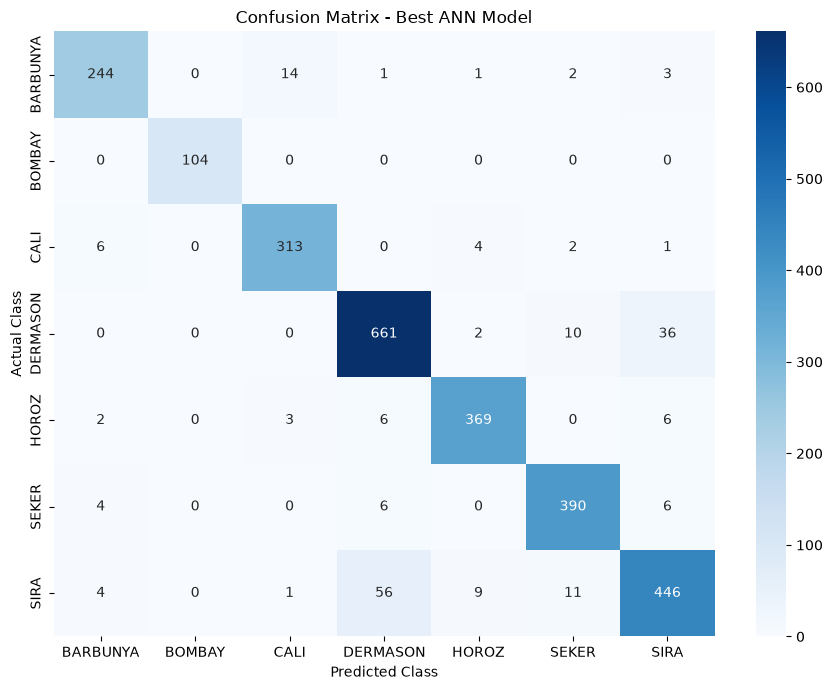

In [37]:
# Generate confusion matrix

best_cm = confusion_matrix(y_test, best_y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    best_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - Best ANN Model")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

# Save confusion matrix
plt.savefig(
    "../figures/ANN_Final_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
# Generate classification report

best_report = classification_report(
    y_test,
    best_y_pred,
    target_names=label_encoder.classes_
)

print("Final ANN Classification Report")
print("--------------------------------")
print(best_report)

Final ANN Classification Report
--------------------------------
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.92      0.93       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.95      0.96      0.95       326
    DERMASON       0.91      0.93      0.92       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.94      0.96      0.95       406
        SIRA       0.90      0.85      0.87       527

    accuracy                           0.93      2723
   macro avg       0.94      0.94      0.94      2723
weighted avg       0.93      0.93      0.93      2723



In [39]:
# Convert classification report into a DataFrame

best_report_dict = classification_report(
    y_test,
    best_y_pred,
    target_names=label_encoder.classes_,
    output_dict=True
)

best_report_df = pd.DataFrame(best_report_dict).transpose()

# Save classification report
best_report_df.to_csv(
    "../results/ANN_Final_Classification_Report.csv"
)

# Convert confusion matrix into a DataFrame

best_cm_df = pd.DataFrame(
    best_cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

# Save confusion matrix
best_cm_df.to_csv(
    "../results/ANN_Final_Confusion_Matrix.csv"
)

print("Final classification report saved!")
print("Final confusion matrix saved!")

Final classification report saved!
Final confusion matrix saved!


In [40]:
# Compare ANN, SVM and Decision Tree

model_comparison = pd.DataFrame({
    "Model": [
        "SVM",
        "SVM",
        "SVM",
        "Decision Tree",
        "ANN"
    ],

    "Configuration": [
        "Linear",
        "Polynomial",
        "RBF",
        "Depth 5",
        "4 Layers - ReLU"
    ],

    "Accuracy": [
        0.921004,
        0.913990,
        0.921004,
        0.874862,
        best_accuracy
    ],

    "F1_Score": [
        0.921001,
        0.915492,
        0.921078,
        0.875483,
        best_f1
    ]
})

print("Model Performance Comparison:")
display(model_comparison.round(4))

# Save comparison
model_comparison.to_csv(
    "../results/ANN_SVM_DT_Comparison.csv",
    index=False
)

Model Performance Comparison:


,Model,Configuration,Accuracy,F1_Score
0,SVM,Linear,0.9210,0.9210
1,SVM,Polynomial,0.9140,0.9155
2,SVM,RBF,0.9210,0.9211
3,Decision Tree,Depth 5,0.8749,0.8755
4,ANN,4 Layers - ReLU,0.9280,0.9398


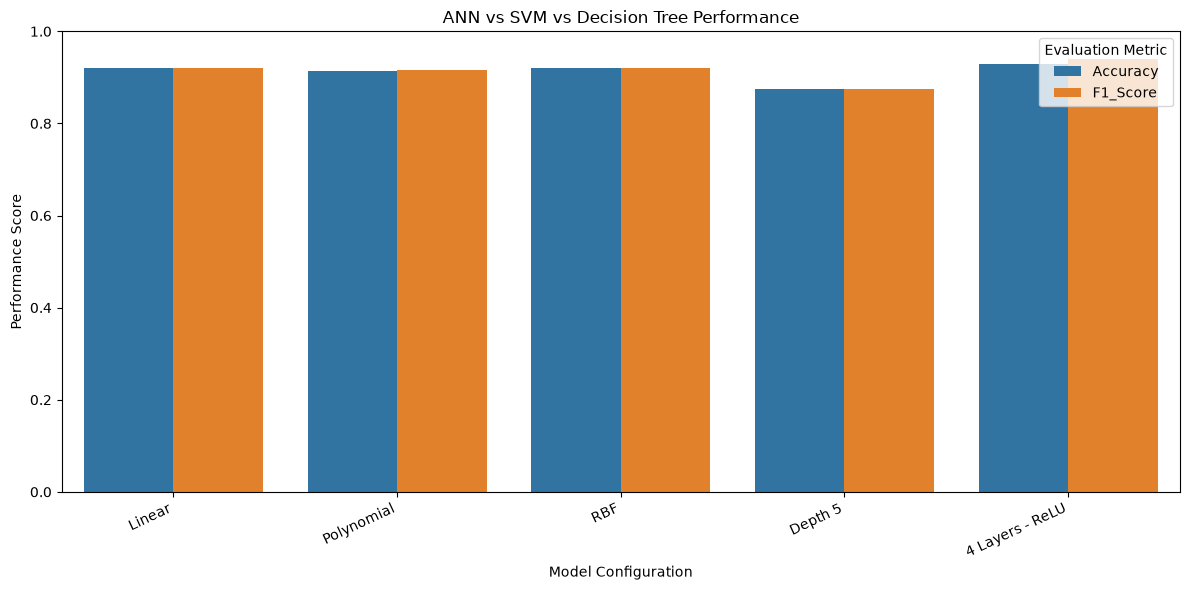

In [41]:
# Prepare data for comparison graph

comparison_plot = model_comparison.melt(
    id_vars=["Model", "Configuration"],
    value_vars=["Accuracy", "F1_Score"],
    var_name="Metric",
    value_name="Score"
)

# Create graph
plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_plot,
    x="Configuration",
    y="Score",
    hue="Metric"
)

plt.title("ANN vs SVM vs Decision Tree Performance")
plt.xlabel("Model Configuration")
plt.ylabel("Performance Score")

plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1)
plt.legend(title="Evaluation Metric")

plt.tight_layout()

# Save graph
plt.savefig(
    "../figures/ANN_SVM_DT_Performance_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Conclusion

In this study, an Artificial Neural Network (ANN) was developed using the Dry Bean dataset to classify seven different varieties of dry beans: BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER and SIRA.

The dataset contained 13,611 observations with 16 numerical input features. The data was divided into training and testing sets using an 80:20 ratio. StandardScaler was applied to standardize the input features, and LabelEncoder was used to encode the target classes.

A total of 81 ANN experiments were conducted by varying the number of hidden layers from 2 to 10, using three activation functions (ReLU, Logistic and Tanh) and three learning rates (0.0001, 0.001 and 0.01).

The experimental results showed that ReLU achieved the highest average Macro F1-score among the three activation functions. The learning rate of 0.01 produced the highest average Macro F1-score, while the architecture with two hidden layers achieved the highest average performance across all its configurations.

Among all 81 experiments, the best individual configuration consisted of four hidden layers with 32 neurons per layer, ReLU activation and a learning rate of 0.01. This model achieved 92.80% accuracy, 94.05% Macro Precision, 93.94% Macro Recall and 93.98% Macro F1-score.

The confusion matrix and classification report demonstrated strong classification performance across the seven bean varieties. However, the SIRA class showed comparatively lower recall, mainly due to confusion with DERMASON.

A comparison with previously obtained SVM and Decision Tree results showed that the ANN achieved the highest recorded accuracy and F1-score among the evaluated configurations.

Overall, this experiment demonstrates the usefulness of Artificial Neural Networks for multiclass classification and highlights the importance of selecting appropriate network architecture, activation function and learning rate. The findings also indicate that increasing the number of hidden layers does not necessarily improve classification performance.